PART-A


In [1]:
print("RITHANYA.G 24BAD132")

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.datasets import mnist

print("TensorFlow Version:", tf.__version__)
print("Libraries Imported Successfully")

RITHANYA.G 24BAD132
TensorFlow Version: 2.21.0
Libraries Imported Successfully


In [2]:
print("RITHANYA.G 24BAD132")

(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("MNIST Dataset Loaded Successfully")
print("Training Images:", x_train.shape)
print("Testing Images:", x_test.shape)
print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)
print("Image Dimensions:", x_train.shape[1:])

RITHANYA.G 24BAD132
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MNIST Dataset Loaded Successfully
Training Images: (60000, 28, 28)
Testing Images: (10000, 28, 28)
Training Labels: (60000,)
Testing Labels: (10000,)
Image Dimensions: (28, 28)


RITHANYA.G 24BAD132


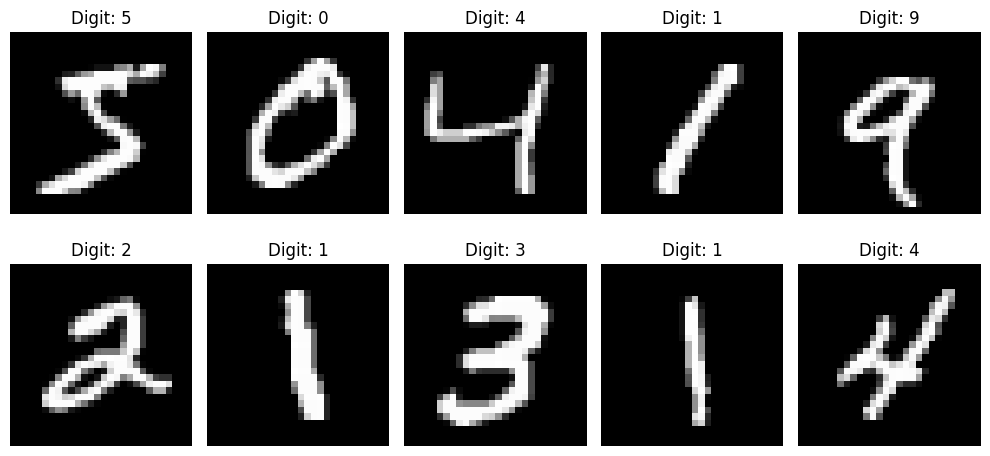

In [3]:
print("RITHANYA.G 24BAD132")

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title("Digit: " + str(y_train[i]))
    plt.axis('off')

plt.tight_layout()
plt.show()

In [4]:
print("RITHANYA.G 24BAD132")

x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

print("Normalization Completed")
print("Minimum Pixel Value:", x_train.min())
print("Maximum Pixel Value:", x_train.max())

RITHANYA.G 24BAD132
Normalization Completed
Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0


In [5]:
print("RITHANYA.G 24BAD132")

x_train_flat = x_train.reshape(60000, 784)
x_test_flat = x_test.reshape(10000, 784)

print("Flattening Completed")
print("Training Data Shape:", x_train_flat.shape)
print("Testing Data Shape:", x_test_flat.shape)

RITHANYA.G 24BAD132
Flattening Completed
Training Data Shape: (60000, 784)
Testing Data Shape: (10000, 784)


In [6]:
print("RITHANYA.G 24BAD132")

x_train_input = x_train_flat
x_train_target = x_train_flat

x_test_input = x_test_flat
x_test_target = x_test_flat

print("Input and Target Data Prepared Successfully")
print("Training Input Shape:", x_train_input.shape)
print("Training Target Shape:", x_train_target.shape)
print("Testing Input Shape:", x_test_input.shape)
print("Testing Target Shape:", x_test_target.shape)

RITHANYA.G 24BAD132
Input and Target Data Prepared Successfully
Training Input Shape: (60000, 784)
Training Target Shape: (60000, 784)
Testing Input Shape: (10000, 784)
Testing Target Shape: (10000, 784)


PART-B


In [7]:
print("RITHANYA.G 24BAD132")

input_dim = 784
latent_dim = 32

input_layer = keras.Input(shape=(input_dim,), name="Input_Layer")

print("Input Layer Created Successfully")
print("Input Dimension:", input_dim)
print("Latent Dimension:", latent_dim)

RITHANYA.G 24BAD132
Input Layer Created Successfully
Input Dimension: 784
Latent Dimension: 32


In [8]:
print("RITHANYA.G 24BAD132")

encoder_hidden = keras.layers.Dense(
    128, activation='relu', name="Encoder_Hidden"
)(input_layer)

latent_layer = keras.layers.Dense(
    latent_dim, activation='relu', name="Latent_Layer"
)(encoder_hidden)

encoder = keras.Model(
    input_layer, latent_layer, name="Encoder"
)

print("Encoder Created Successfully")
encoder.summary()

RITHANYA.G 24BAD132
Encoder Created Successfully


Model: "Encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_Layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Encoder_Hidden (Dense)          │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Latent_Layer (Dense)            │ (None, 32)             │         4,128 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 104,608 (408.62 KB)

 Trainable params: 104,608 (408.62 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
print("RITHANYA.G 24BAD132")

decoder_input = keras.Input(shape=(latent_dim,), name="Decoder_Input")

decoder_hidden = keras.layers.Dense(
    128, activation='relu', name="Decoder_Hidden"
)(decoder_input)

decoder_output = keras.layers.Dense(
    784, activation='sigmoid', name="Reconstructed_Output"
)(decoder_hidden)

decoder = keras.Model(
    decoder_input, decoder_output, name="Decoder"
)

print("Decoder Created Successfully")
decoder.summary()

RITHANYA.G 24BAD132
Decoder Created Successfully


Model: "Decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Decoder_Input (InputLayer)      │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Decoder_Hidden (Dense)          │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Reconstructed_Output (Dense)    │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 105,360 (411.56 KB)

 Trainable params: 105,360 (411.56 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
print("RITHANYA.G 24BAD132")

autoencoder_output = decoder(encoder(input_layer))

autoencoder = keras.Model(
    input_layer, autoencoder_output, name="Autoencoder"
)

print("Complete Autoencoder Created Successfully")
autoencoder.summary()

RITHANYA.G 24BAD132
Complete Autoencoder Created Successfully


Model: "Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_Layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Encoder (Functional)            │ (None, 32)             │       104,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Decoder (Functional)            │ (None, 784)            │       105,360 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
print("RITHANYA.G 24BAD132")

print("\nENCODER MODEL SUMMARY")
encoder.summary()

print("\nDECODER MODEL SUMMARY")
decoder.summary()

print("\nCOMPLETE AUTOENCODER MODEL SUMMARY")
autoencoder.summary()

RITHANYA.G 24BAD132

ENCODER MODEL SUMMARY


Model: "Encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_Layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Encoder_Hidden (Dense)          │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Latent_Layer (Dense)            │ (None, 32)             │         4,128 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 104,608 (408.62 KB)

 Trainable params: 104,608 (408.62 KB)

 Non-trainable params: 0 (0.00 B)

... (8 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_Layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Encoder (Functional)            │ (None, 32)             │       104,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Decoder (Functional)            │ (None, 784)            │       105,360 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

PART-C


In [12]:
print("RITHANYA.G 24BAD132")

autoencoder.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['mse']
)

print("Autoencoder Compiled Successfully")

RITHANYA.G 24BAD132
Autoencoder Compiled Successfully


In [13]:
print("RITHANYA.G 24BAD132")

history = autoencoder.fit(
    x_train_input,
    x_train_target,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test_input, x_test_target)
)

print("Autoencoder Training Completed Successfully")

RITHANYA.G 24BAD132
Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 25ms/step - loss: 0.2351 - mse: 0.0570 - val_loss: 0.1559 - val_mse: 0.0310
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.1391 - mse: 0.0252 - val_loss: 0.1252 - val_mse: 0.0208
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - loss: 0.1202 - mse: 0.0189 - val_loss: 0.1135 - val_mse: 0.0168
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - loss: 0.1120 - mse: 0.0163 - val_loss: 0.1076 - val_mse: 0.0149
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.1073 - mse: 0.0148 - val_loss: 0.1042 - val_mse: 0.0138
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 0.1046 - mse: 0.0139 - val_loss: 0.1022 - val_mse: 0.0132
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.1031 - mse: 0.0134 - val_loss: 0.1011 - val_mse: 0.0128
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.1019 - mse: 0.0130 - val_loss: 0.1002 - val_mse: 0.0126
Epoch 9/10
235/235 ━━━━━━━━━

In [14]:
print("RITHANYA.G 24BAD132")

print("Training Loss for Each Epoch:")
print(history.history['loss'])

print("\nValidation Loss for Each Epoch:")
print(history.history['val_loss'])

RITHANYA.G 24BAD132
Training Loss for Each Epoch:
[0.23512838780879974, 0.13908599317073822, 0.12019197642803192, 0.11203479766845703, 0.10728223621845245, 0.10461603850126266, 0.10305735468864441, 0.10187481343746185, 0.10079754143953323, 0.09992174804210663]

Validation Loss for Each Epoch:
[0.15592540800571442, 0.125179260969162, 0.11351098865270615, 0.10758958756923676, 0.10415355116128922, 0.10223572701215744, 0.10108276456594467, 0.10024084150791168, 0.09901412576436996, 0.09843573719263077]


RITHANYA.G 24BAD132


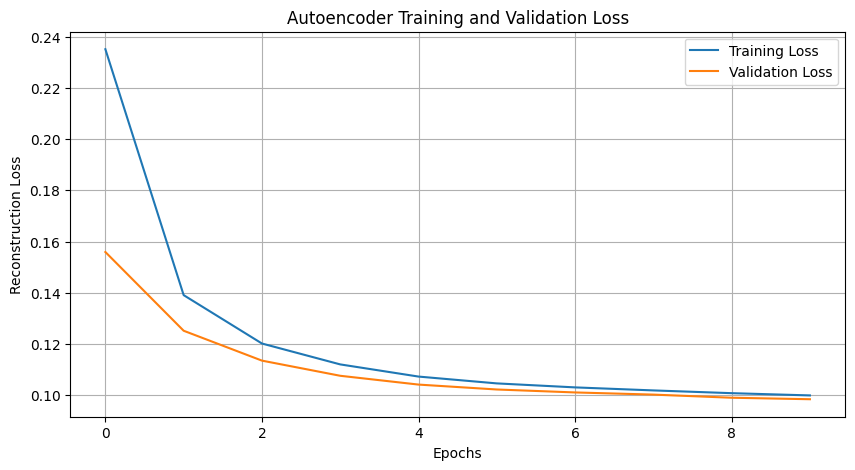

In [15]:
print("RITHANYA.G 24BAD132")

plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Autoencoder Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Reconstruction Loss')
plt.legend()
plt.grid(True)

plt.show()

In [16]:
print("RITHANYA.G 24BAD132")

test_loss, test_mse = autoencoder.evaluate(
    x_test_input,
    x_test_target,
    verbose=0
)

print("Autoencoder Evaluation Completed")
print("Test Reconstruction Loss:", test_loss)
print("Test Mean Squared Error:", test_mse)

RITHANYA.G 24BAD132
Autoencoder Evaluation Completed
Test Reconstruction Loss: 0.09843572229146957
Test Mean Squared Error: 0.011986156925559044


PART-D

In [17]:
print("RITHANYA.G 24BAD132")

latent_features = encoder.predict(x_test_input)

print("Latent Features Extracted Successfully")
print("Original Input Dimension:", x_test_input.shape[1])
print("Latent Feature Dimension:", latent_features.shape[1])
print("Latent Feature Shape:", latent_features.shape)

RITHANYA.G 24BAD132
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Latent Features Extracted Successfully
Original Input Dimension: 784
Latent Feature Dimension: 32
Latent Feature Shape: (10000, 32)


In [18]:
print("RITHANYA.G 24BAD132")

original_dimension = 784
latent_dimension = 32

reduction_percentage = (
    (original_dimension - latent_dimension) / original_dimension
) * 100

print("Original Dimension:", original_dimension)
print("Latent Dimension:", latent_dimension)
print("Dimensionality Reduction:", round(reduction_percentage, 2), "%")

RITHANYA.G 24BAD132
Original Dimension: 784
Latent Dimension: 32
Dimensionality Reduction: 95.92 %


In [19]:
print("RITHANYA.G 24BAD132")

reconstructed_images = decoder.predict(latent_features)

print("Image Reconstruction Completed Successfully")
print("Reconstructed Image Shape:", reconstructed_images.shape)

RITHANYA.G 24BAD132
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Image Reconstruction Completed Successfully
Reconstructed Image Shape: (10000, 784)


RITHANYA.G 24BAD132


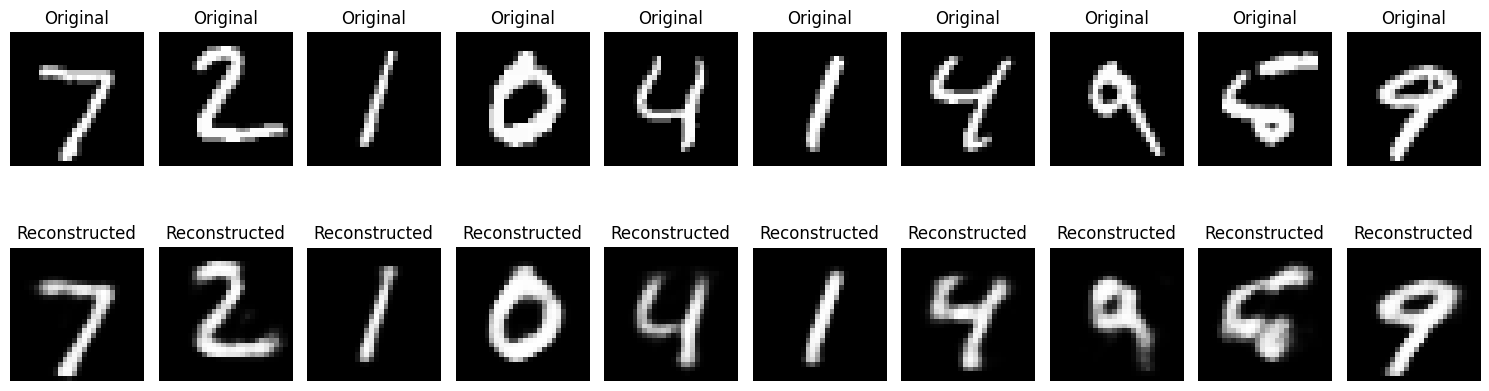

In [20]:
print("RITHANYA.G 24BAD132")

plt.figure(figsize=(15, 5))

for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i], cmap='gray')
    plt.title("Original")
    plt.axis('off')

    plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructed_images[i].reshape(28, 28), cmap='gray')
    plt.title("Reconstructed")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [21]:
print("RITHANYA.G 24BAD132")

reconstructed_flat = reconstructed_images

mse = np.mean((x_test_input - reconstructed_flat) ** 2)

print("Reconstruction Comparison Completed")
print("Mean Squared Error:", mse)

RITHANYA.G 24BAD132
Reconstruction Comparison Completed
Mean Squared Error: 0.011986164


RITHANYA.G 24BAD132


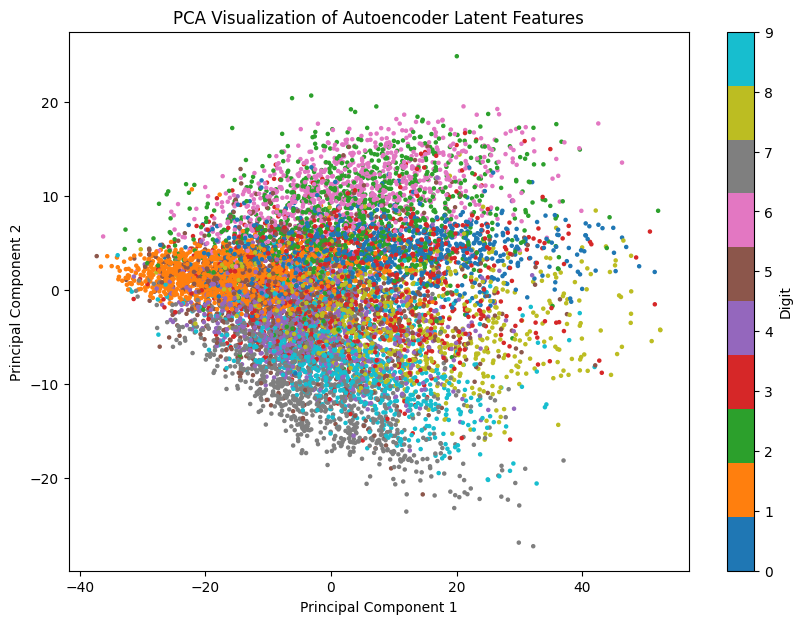

PCA Visualization Completed Successfully


In [22]:
print("RITHANYA.G 24BAD132")

from sklearn.decomposition import PCA

pca = PCA(n_components=2)

latent_2d = pca.fit_transform(latent_features)

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    latent_2d[:, 0],
    latent_2d[:, 1],
    c=y_test,
    cmap='tab10',
    s=5
)

plt.colorbar(scatter, label='Digit')
plt.title("PCA Visualization of Autoencoder Latent Features")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

print("PCA Visualization Completed Successfully")

In [23]:
print("RITHANYA.G 24BAD132")

autoencoder.save("MNIST_Autoencoder_RITHANYA.keras")

np.save(
    "MNIST_Latent_Features_RITHANYA.npy",
    latent_features
)

np.save(
    "MNIST_Reconstructed_Images_RITHANYA.npy",
    reconstructed_images
)

print("Autoencoder Model Saved Successfully")
print("Latent Features Saved Successfully")
print("Reconstructed Images Saved Successfully")

RITHANYA.G 24BAD132
Autoencoder Model Saved Successfully
Latent Features Saved Successfully
Reconstructed Images Saved Successfully
